# HSA_Cam_B_004.py
This file uses the LHHW_Model of kinetics to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_003.py is the model. This uses homoscedastic noise.

## First try to actually infer the model

### Plan:
* generate data
* instantiate the model
* infer the model
* check HDIs
* select next experiment at highest HDI

### Results:
* Inference works
* HDIs work
* max HDI strategy does work better now 
* the priors are not updated significantly, which is really bad
* use exponential priors for the kinetic parameters
* next step: implement relative HDI

In [1]:
import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm
import pytensor

import arviz as az
from scipy.optimize import minimize

pytensor.config.mode = "JAX"

In [2]:
from HSA_Cam_B_003 import (
    SIDX,
    TRUE_PARAMS,
    _kinetics_model,
    input_p,
    bmodel,
)

In [3]:
def post_model_over_T(proposal, idata, key="posterior"):

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        "k0": idata[key]["k0"].values.reshape(1, -1),
        "Ea_k": idata[key]["Ea_k"].values.reshape(1, -1),
        "A_oh": idata[key]["A_oh"].values.reshape(1, -1),
        "dH_oh": idata[key]["dH_oh"].values.reshape(1, -1),
        "A_h2": idata[key]["A_h2"].values.reshape(1, -1),
        "dH_h2": idata[key]["dH_h2"].values.reshape(1, -1),
        "A_mix": idata[key]["A_mix"].values.reshape(1, -1),
        "dH_mix": idata[key]["dH_mix"].values.reshape(1, -1),
    }

    test_res = _kinetics_model(**test_params)
    return test_res


def true_model_over_T(proposal):
    true_res_T = _kinetics_model(
        input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        *TRUE_PARAMS.values(),
    )
    return true_res_T

In [4]:
def plot_post_model_at_proposal(test_res, true_res, Ts):
    plt.plot(
        Ts,
        test_res.mean(axis=1),
    )
    plt.plot(
        Ts,
        true_res.squeeze(),
        color="black",
        linestyle="--",
    )
    plt.fill_between(
        x=Ts,
        y1=np.percentile(test_res, 2.5, axis=1),
        y2=np.percentile(test_res, 97.5, axis=1),
        alpha=0.3,
        zorder=0,
    )
    ax = plt.gca()
    ax2 = ax.twinx()
    ax2.plot(
        Ts,
        np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
        color="orange",
    )

In [5]:
def observe_at_proposal(proposals):
    T = jnp.array([proposals[:, 0]], dtype=jnp.float32).reshape(-1, 1)
    p = jnp.array([proposals[:, 1]], dtype=jnp.float32).reshape(-1, 1)
    c2h = jnp.array([proposals[:, 2]], dtype=jnp.float32).reshape(-1, 1)
    f = jnp.array([proposals[:, 3]], dtype=jnp.float32).reshape(-1, 1)
    c2i = jnp.array([proposals[:, 4]], dtype=jnp.float32).reshape(-1, 1)

    p_i = input_p(p, c2h, f, c2i)

    r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
    r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
    return T, p, c2h, f, c2i, r_obs

In [6]:
T = jnp.array([560, 570, 580], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array([4, 5, 6], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array([1], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array([1000], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array([0.5], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
print(r)
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
print(r_obs)

[[9.99750078e-01 9.99750078e-01 0.00000000e+00 9.99750078e-04
  1.99950016e+00]
 [1.24968760e+00 1.24968760e+00 0.00000000e+00 1.24968760e-03
  2.49937519e+00]
 [1.49962512e+00 1.49962512e+00 0.00000000e+00 1.49962512e-03
  2.99925023e+00]]
[[7.61192633e-05]
 [1.16399861e-04]
 [1.72598760e-04]]
[[8.56923350e-05]
 [1.06700571e-04]
 [1.82669424e-04]]


In [7]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = input_p(p, c2h, f, c2i)
    res = _kinetics_model(
        p_i,
        T,
        idata[key]["k0"].values.reshape(1, -1),
        idata[key]["Ea_k"].values.reshape(1, -1),
        idata[key]["A_oh"].values.reshape(1, -1),
        idata[key]["dH_oh"].values.reshape(1, -1),
        idata[key]["A_h2"].values.reshape(1, -1),
        idata[key]["dH_h2"].values.reshape(1, -1),
        idata[key]["A_mix"].values.reshape(1, -1),
        idata[key]["dH_mix"].values.reshape(1, -1),
    )
    HDI = jnp.percentile(res, 97.5) - jnp.percentile(res, 2.5)
    return -HDI

In [8]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [9]:
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\jax\linker.py:32: UserWarning: The RandomType SharedVariables [RNG(<Generator(PCG64) at 0x146DD44C900>), RNG(<Generator(PCG64) at 0x146DD44C820>), RNG(<Generator(PCG64) at 0x146DD44C200>), RNG(<Generator(PCG64) at 0x146DC261A80>), RNG(<Generator(PCG64) at 0x146DD44CAC0>), RNG(<Generator(PCG64) at 0x146DD56C9E0>), RNG(<Generator(PCG64) at 0x146DD44C740>), RNG(<Generator(PCG64) at 0x146DD44C9E0>), RNG(<Generator(PCG64) at 0x146DD44C580>), RNG(<Generator(PCG64) at 0x146DD44C660>)] will not be used in the compiled JAX graph. Instead a copy will be used.
  warnings.warn(
Sampling: [A_h2, A_mix, A_oh, Ea_k, LH2, dH_h2, dH_mix, dH_oh, k0, sigma_r]


In [10]:
# sol = minimize(
#     max_func,
#     jnp.array([555.0, 15.0, 0.5, 1000.0, 0.5]),
#     args=(prior_idata, "prior"),
#     bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
#     method="Nelder-Mead",
# )
# proposals = np.atleast_2d(sol.x)
# print(proposals)

generate the first 4 points on purpose

In [13]:
proposals = np.array(
    [
        [500.0, 4.0, 0.5, 1000.0, 0.5],
        [600.0, 4.0, 0.5, 1000.0, 0.5],
        [500.0, 20.0, 0.5, 1000.0, 0.5],
        [600.0, 20.0, 0.5, 1000.0, 0.5],
    ]
)

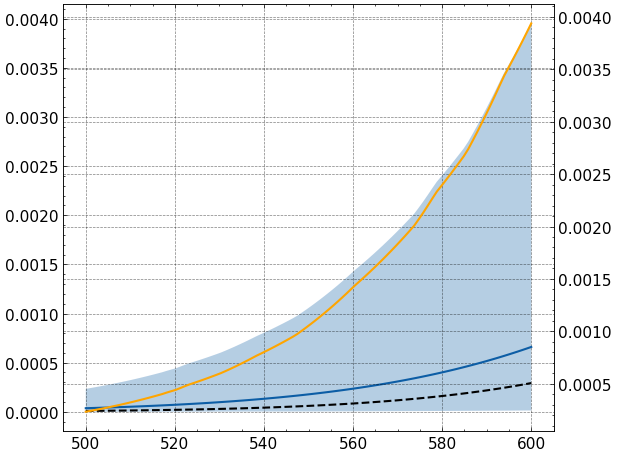

In [14]:
Ts = jnp.linspace(500, 600, 100)
test_res = post_model_over_T(proposals[0], prior_idata, key="prior")
true_res = true_model_over_T(proposals[0])
plot_post_model_at_proposal(test_res, true_res, Ts)

# First Conditioning step

In [15]:
T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 164 seconds.
There were 214 divergences after tuning. Increase `target_accept` or reparameterize.


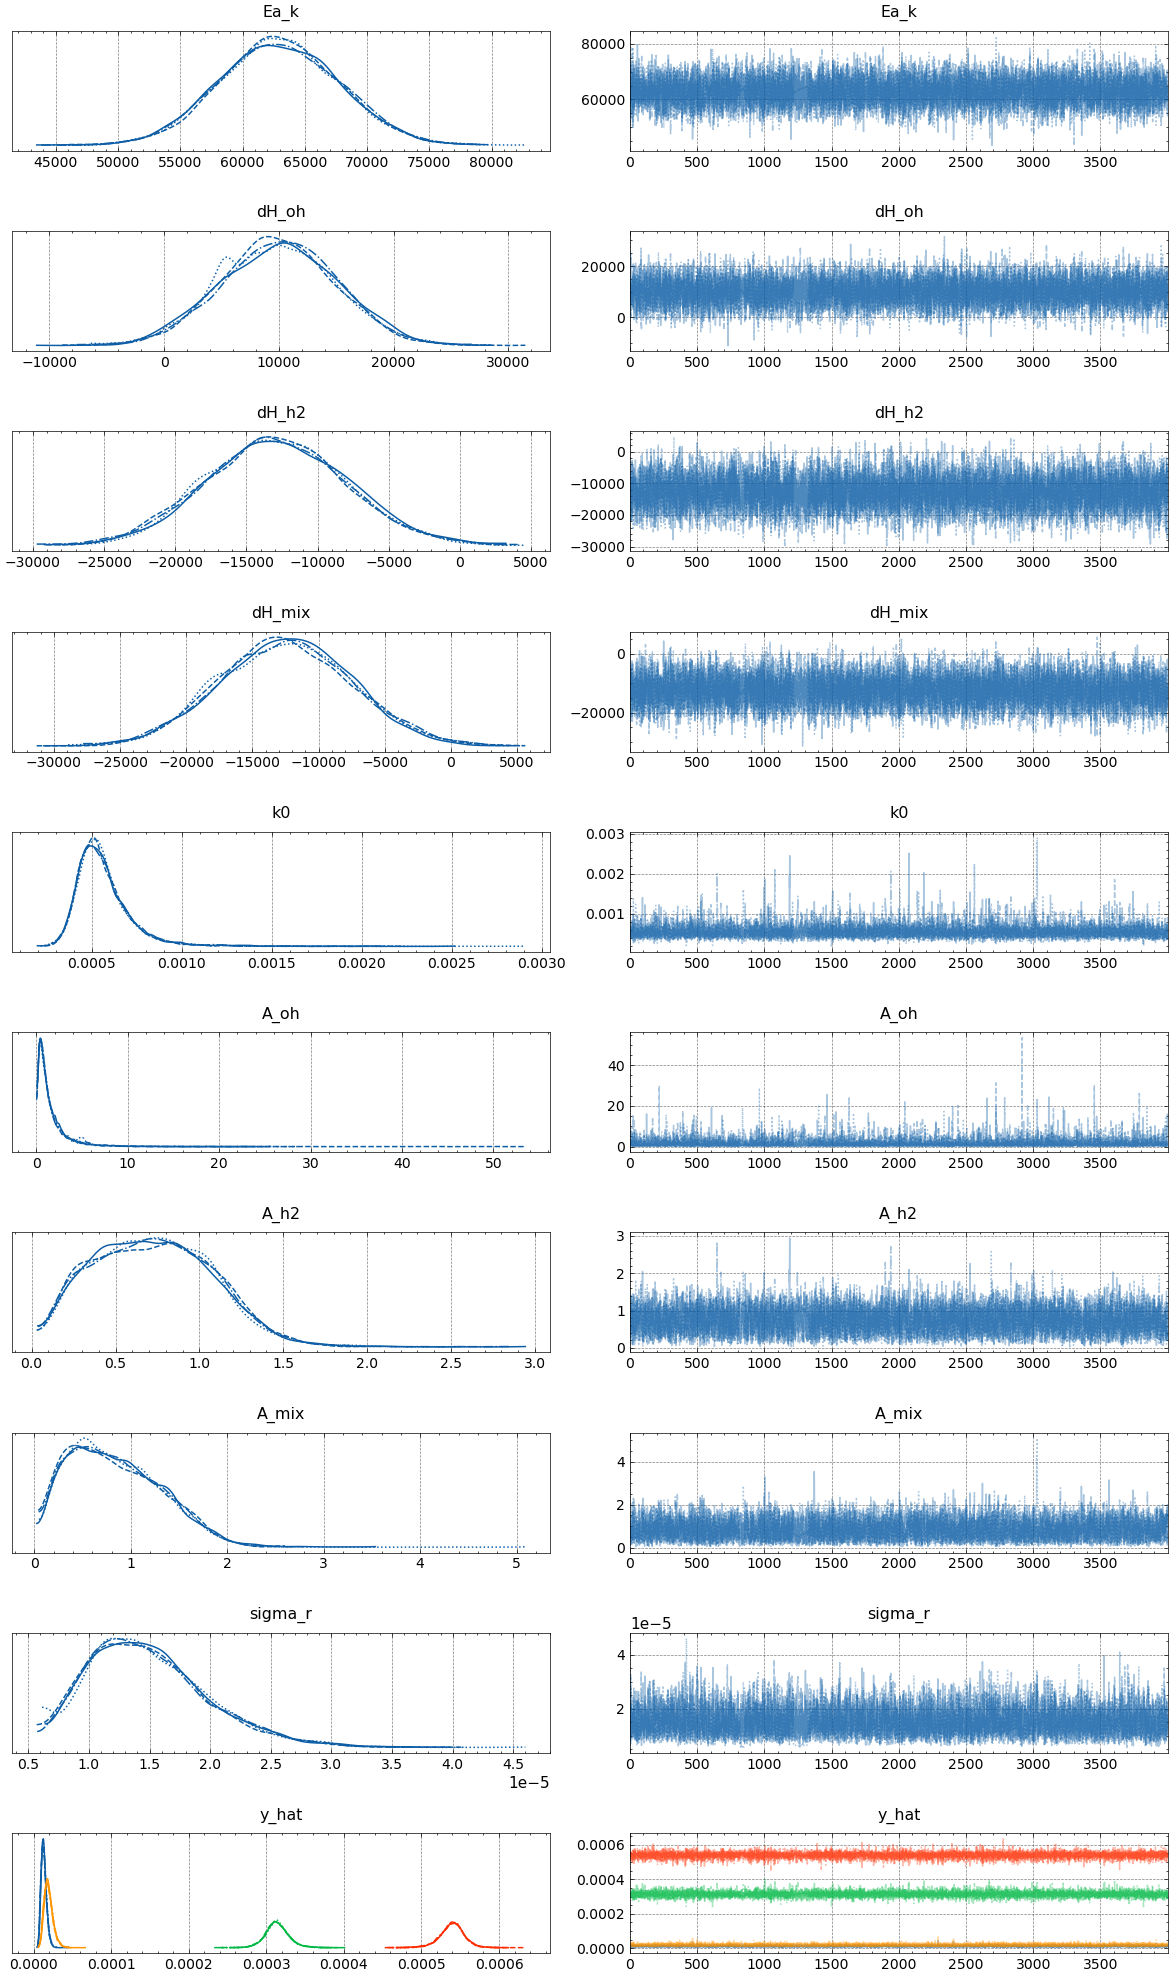

In [16]:
az.plot_trace(idata, divergences=False)
plt.show()

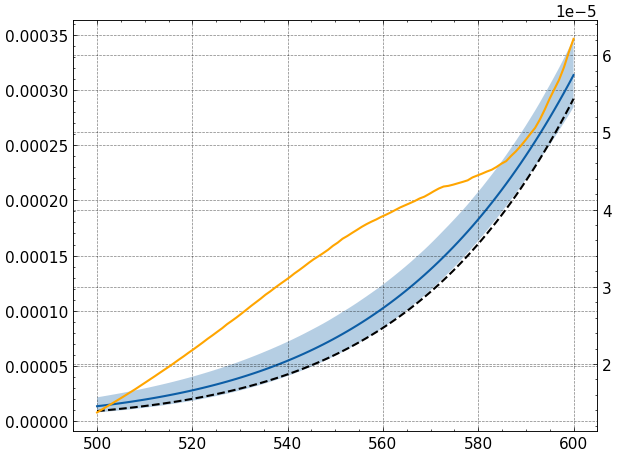

In [17]:
test_res = post_model_over_T(proposals[0], idata, key="posterior")
true_res_T = true_model_over_T(proposals[0])
plot_post_model_at_proposal(test_res, true_res_T, Ts)

In [18]:
sol = minimize(
    max_func,
    jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
print(proposals)

[[5.00000000e+02 4.00000000e+00 5.00000000e-01 1.00000000e+03
  5.00000000e-01]
 [6.00000000e+02 4.00000000e+00 5.00000000e-01 1.00000000e+03
  5.00000000e-01]
 [5.00000000e+02 2.00000000e+01 5.00000000e-01 1.00000000e+03
  5.00000000e-01]
 [6.00000000e+02 2.00000000e+01 5.00000000e-01 1.00000000e+03
  5.00000000e-01]
 [6.00000000e+02 2.00000000e+01 1.99999683e+00 1.00000000e+03
  9.99979096e-01]]


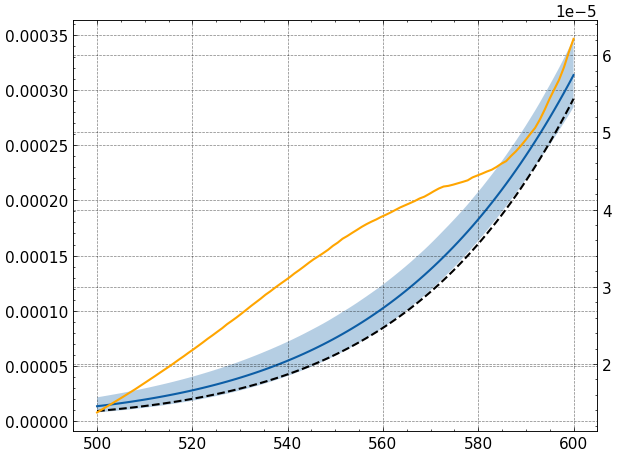

In [19]:
test_res = post_model_over_T(proposals[1], idata, key="posterior")
true_res_T = true_model_over_T(proposals[1])
plot_post_model_at_proposal(test_res, true_res_T, Ts)

# Second Sampling step

In [20]:
T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)

In [21]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [22]:
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 106 seconds.
There were 266 divergences after tuning. Increase `target_accept` or reparameterize.


array([[<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'dH_oh'}>,
        <Axes: title={'center': 'dH_oh'}>],
       [<Axes: title={'center': 'dH_h2'}>,
        <Axes: title={'center': 'dH_h2'}>],
       [<Axes: title={'center': 'dH_mix'}>,
        <Axes: title={'center': 'dH_mix'}>],
       [<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'A_oh'}>,
        <Axes: title={'center': 'A_oh'}>],
       [<Axes: title={'center': 'A_h2'}>,
        <Axes: title={'center': 'A_h2'}>],
       [<Axes: title={'center': 'A_mix'}>,
        <Axes: title={'center': 'A_mix'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>],
       [<Axes: title={'center': 'y_hat'}>,
        <Axes: title={'center': 'y_hat'}>]], dtype=object)

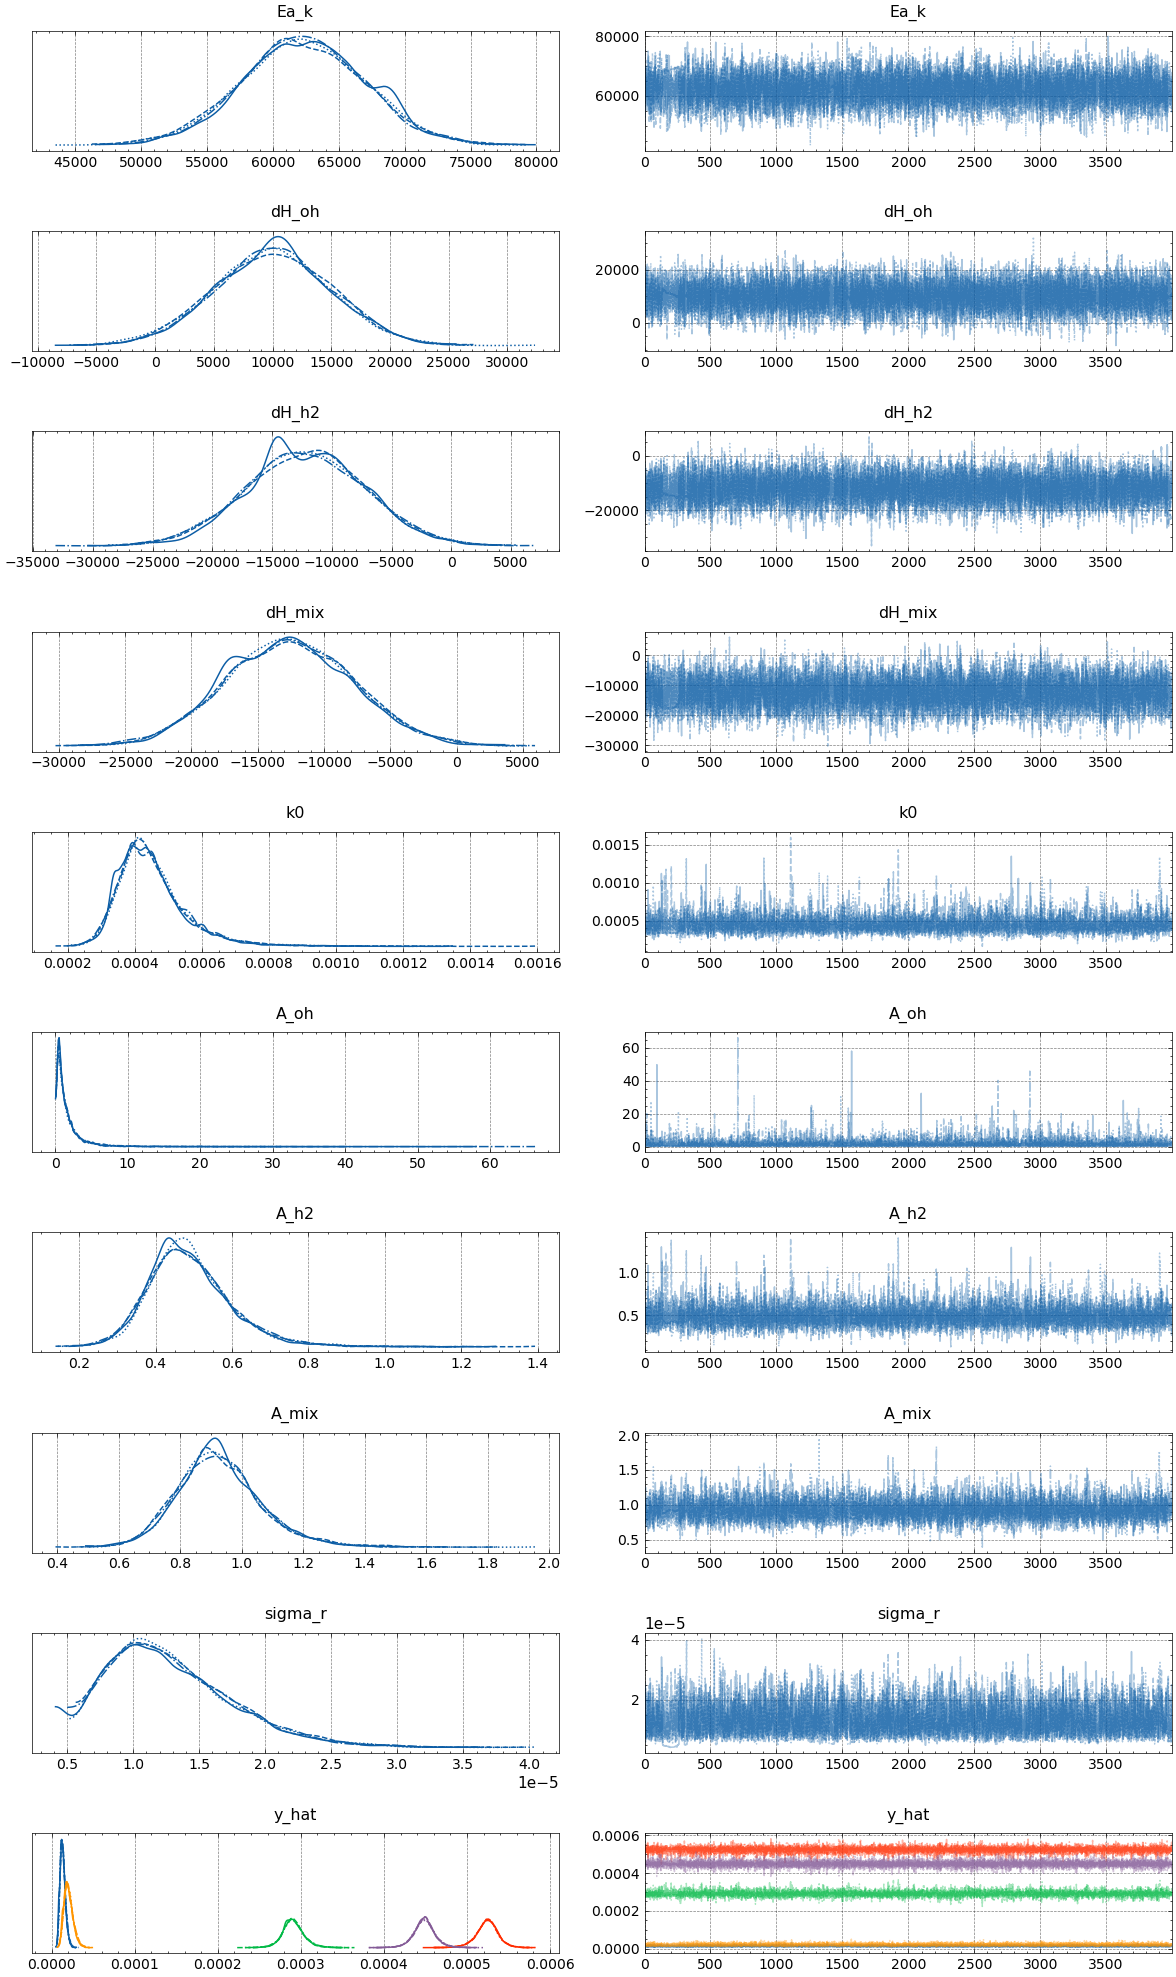

In [23]:
az.plot_trace(idata, divergences=False)

In [24]:
test_res = post_model_over_T(proposals[-1], idata, key="posterior")
true_res = true_model_over_T(proposals[-1])

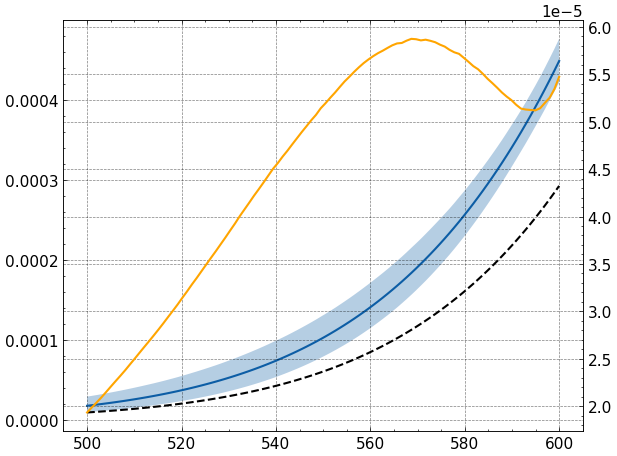

In [25]:
plot_post_model_at_proposal(test_res, true_res_T, Ts)

In [26]:
sol = minimize(
    max_func,
    jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[5.00000000e+02, 4.00000000e+00, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 4.00000000e+00, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [5.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 2.00000000e+01, 1.99999683e+00, 1.00000000e+03,
        9.99979096e-01],
       [5.69013891e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00]])

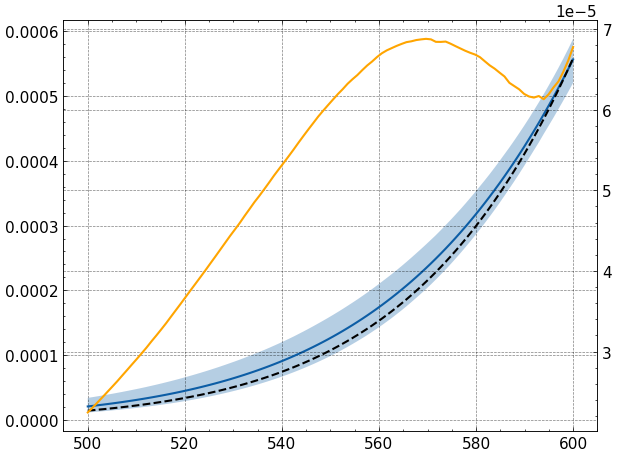

In [27]:
test_res = post_model_over_T(proposals[-1], idata, key="posterior")
true_res = true_model_over_T(proposals[-1])
plot_post_model_at_proposal(test_res, true_res, Ts)

# third conditioning step

In [28]:
T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)

In [29]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [30]:
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 122 seconds.
There were 1024 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


array([[<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'dH_oh'}>,
        <Axes: title={'center': 'dH_oh'}>],
       [<Axes: title={'center': 'dH_h2'}>,
        <Axes: title={'center': 'dH_h2'}>],
       [<Axes: title={'center': 'dH_mix'}>,
        <Axes: title={'center': 'dH_mix'}>],
       [<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'A_oh'}>,
        <Axes: title={'center': 'A_oh'}>],
       [<Axes: title={'center': 'A_h2'}>,
        <Axes: title={'center': 'A_h2'}>],
       [<Axes: title={'center': 'A_mix'}>,
        <Axes: title={'center': 'A_mix'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>],
       [<Axes: title={'center': 'y_hat'}>,
        <Axes: title={'center': 'y_hat'}>]], dtype=object)

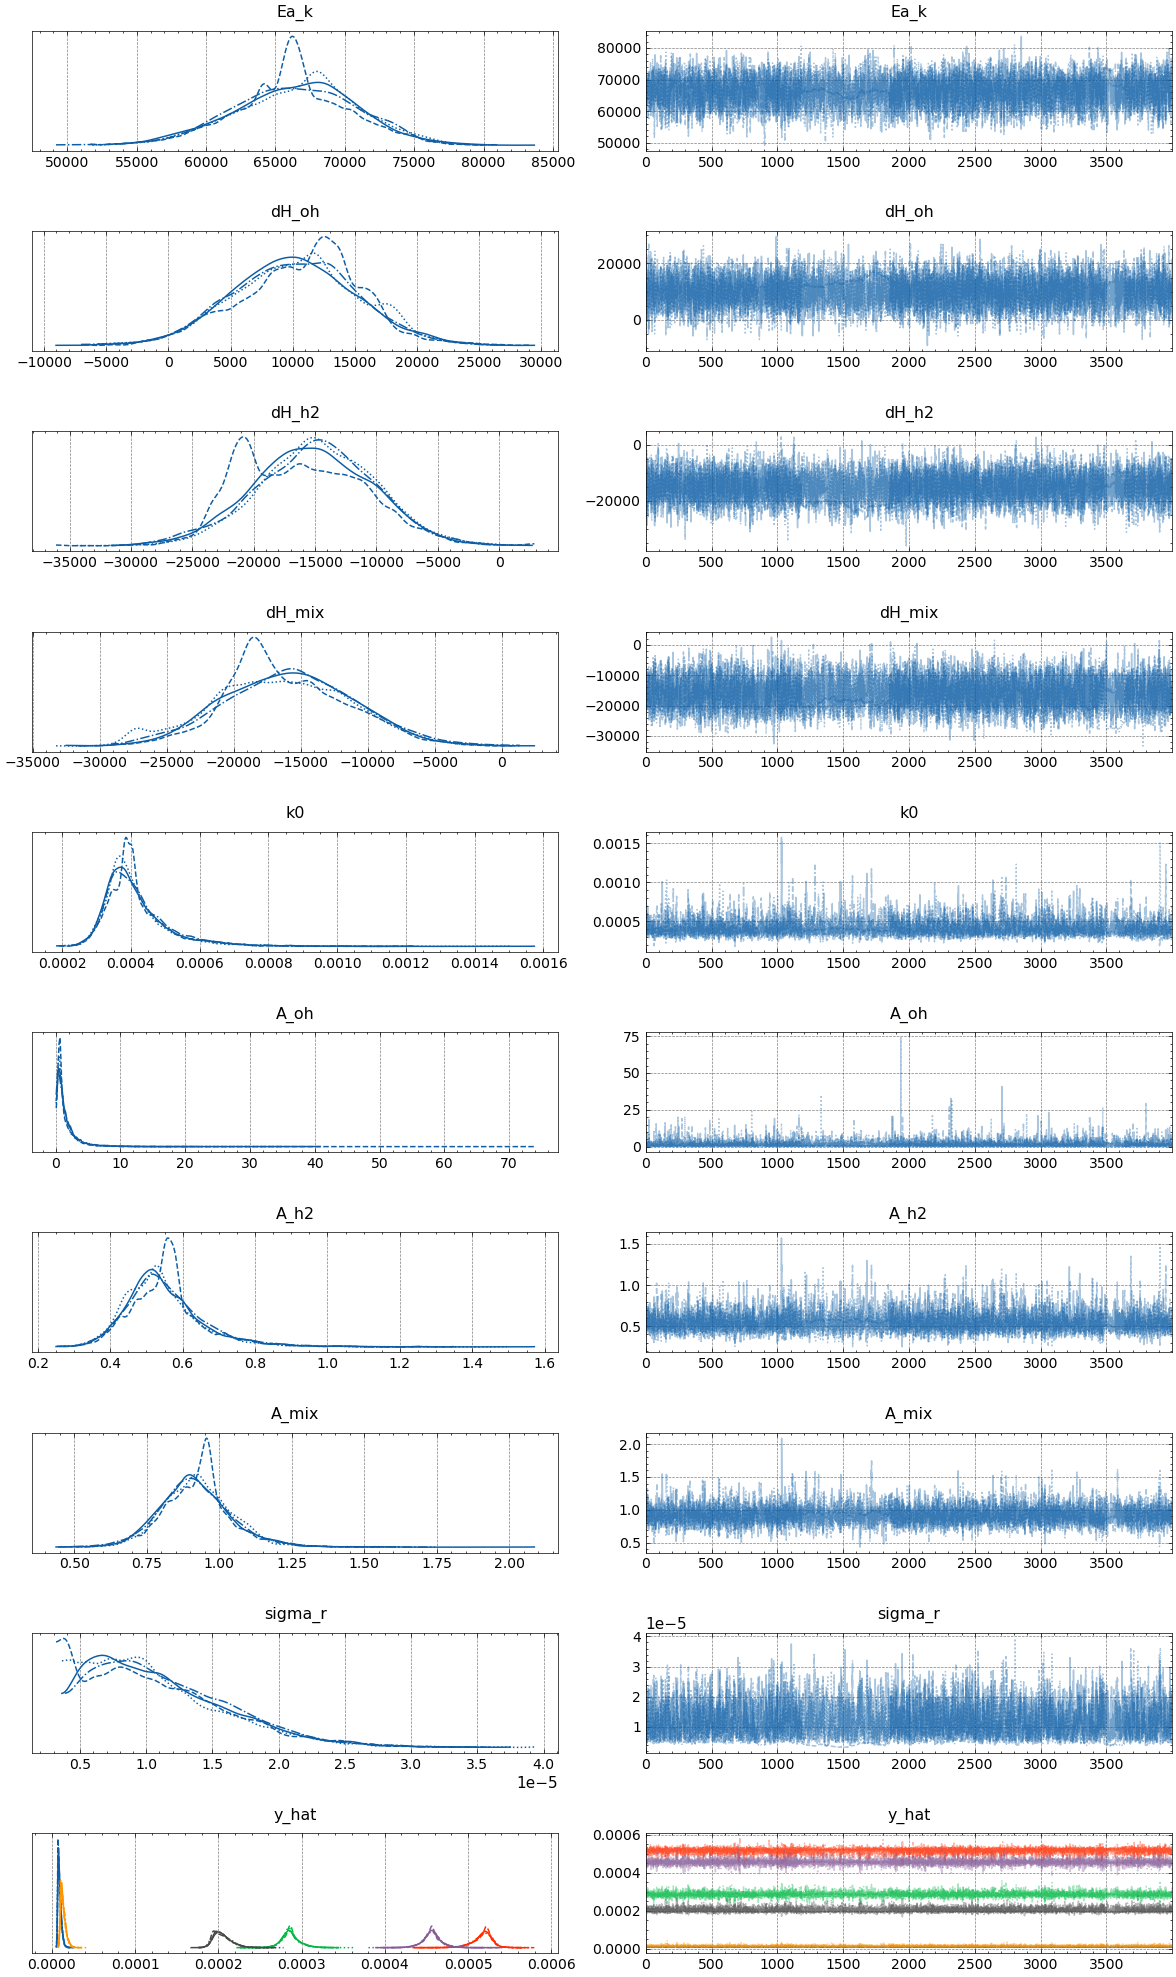

In [31]:
az.plot_trace(idata, divergences=False)

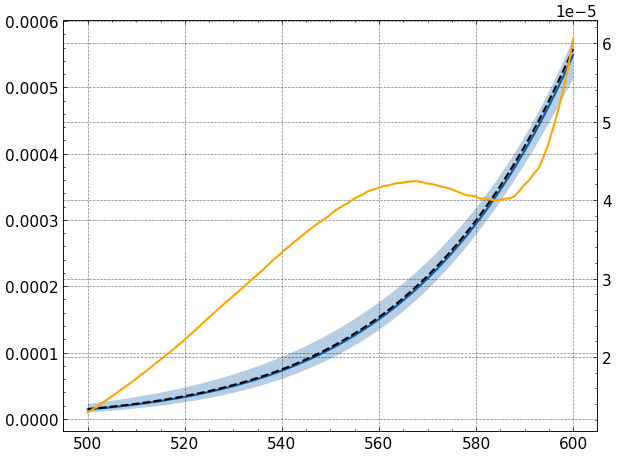

In [32]:
test_res = post_model_over_T(proposals[-1], idata, key="posterior")
true_res = true_model_over_T(proposals[-1])
plot_post_model_at_proposal(test_res, true_res, Ts)

In [33]:
sol = minimize(
    max_func,
    jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[5.00000000e+02, 4.00000000e+00, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 4.00000000e+00, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [5.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 2.00000000e+01, 1.99999683e+00, 1.00000000e+03,
        9.99979096e-01],
       [5.69013891e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [5.74456740e+02, 2.00000000e+01, 2.00000000e+00, 1.00000000e+03,
        1.00000000e+00]])

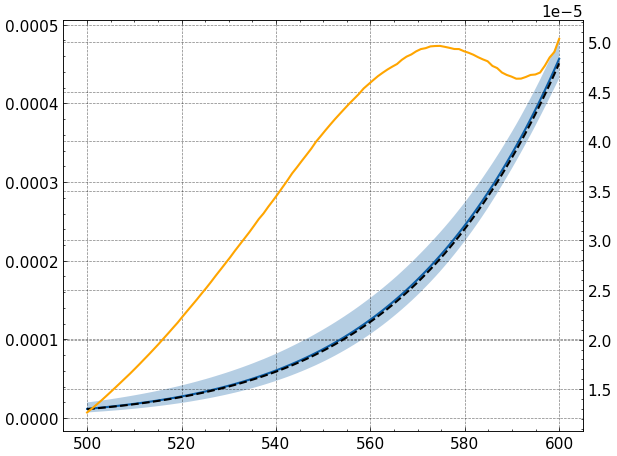

In [34]:
test_res = post_model_over_T(proposals[-1], idata, key="posterior")
true_res = true_model_over_T(proposals[-1])
plot_post_model_at_proposal(test_res, true_res, Ts)

# Fourth Conditioning Step

In [35]:
T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)

In [36]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [37]:
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 132 seconds.
There were 649 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


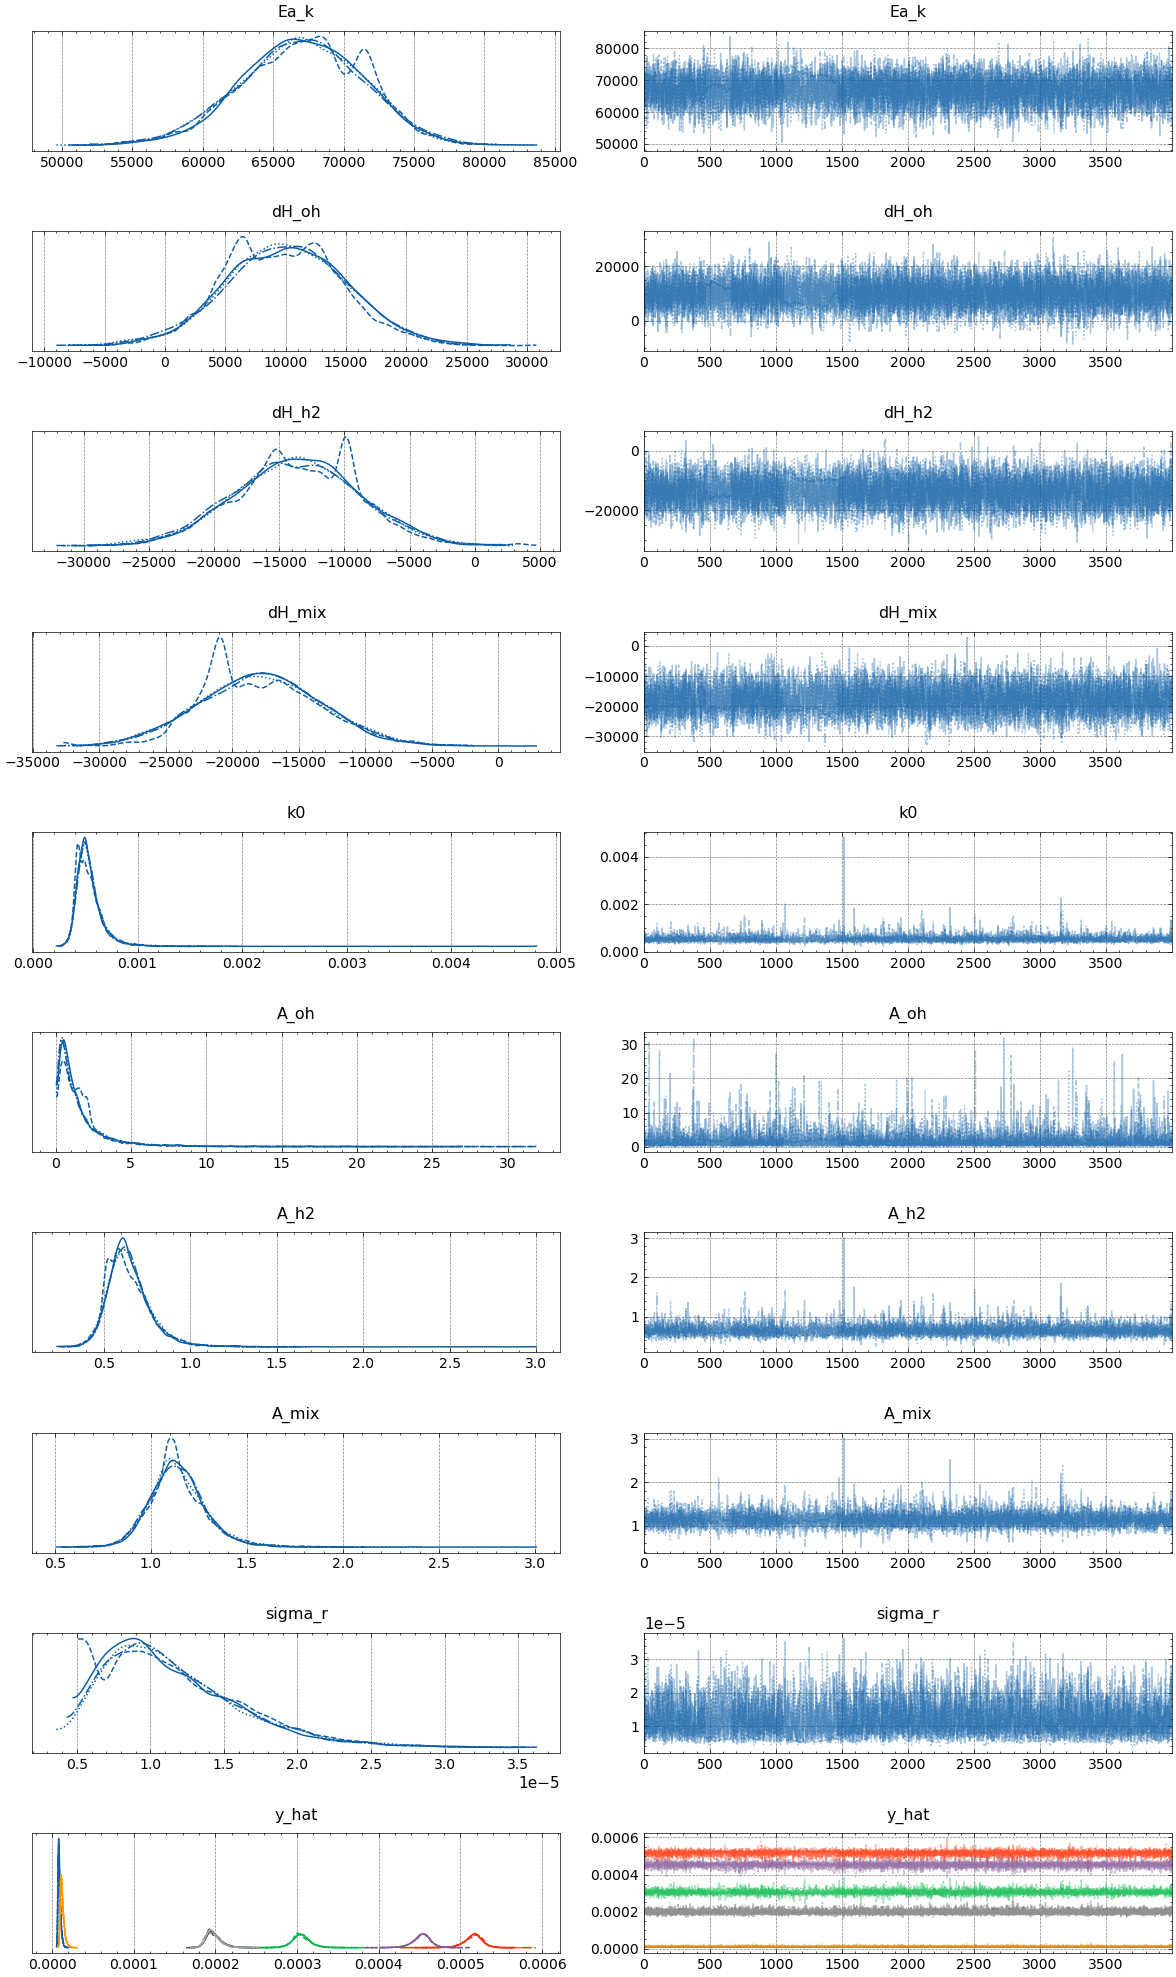

In [38]:
az.plot_trace(idata, divergences=False)
plt.show()

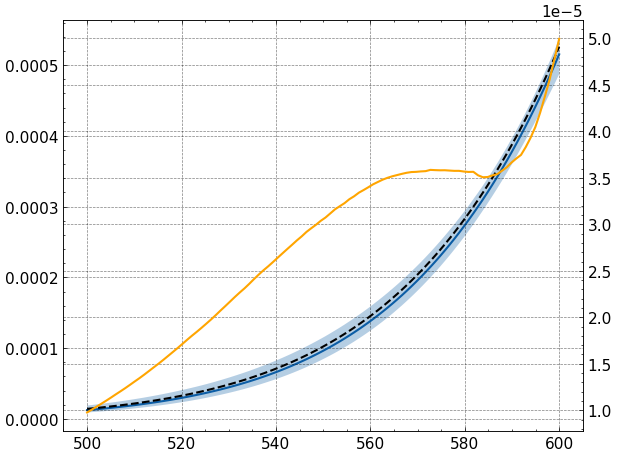

In [39]:
test_res = post_model_over_T(proposals[3], idata, key="posterior")
true_res = true_model_over_T(proposals[3])
plot_post_model_at_proposal(test_res, true_res, Ts)

In [40]:
sol = minimize(
    max_func,
    jnp.array([555.0, 10.0, 1.0, 100, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[5.00000000e+02, 4.00000000e+00, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 4.00000000e+00, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [5.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 2.00000000e+01, 1.99999683e+00, 1.00000000e+03,
        9.99979096e-01],
       [5.69013891e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [5.74456740e+02, 2.00000000e+01, 2.00000000e+00, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 3.28278965e+00, 1.73911836e+00, 8.92865756e+01,
        4.03215669e-01]])

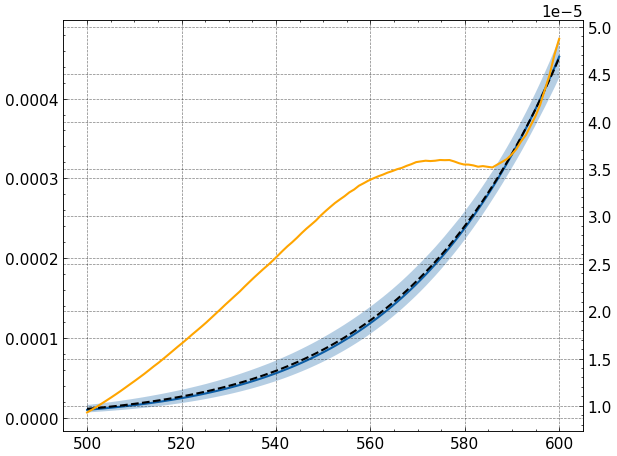

In [41]:
test_res = post_model_over_T(proposals[4], idata, key="posterior")
true_res = true_model_over_T(proposals[4])
plot_post_model_at_proposal(test_res, true_res, Ts)

# Fifth Sampling Step

In [42]:
T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)

In [43]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [44]:
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 116 seconds.
There were 432 divergences after tuning. Increase `target_accept` or reparameterize.


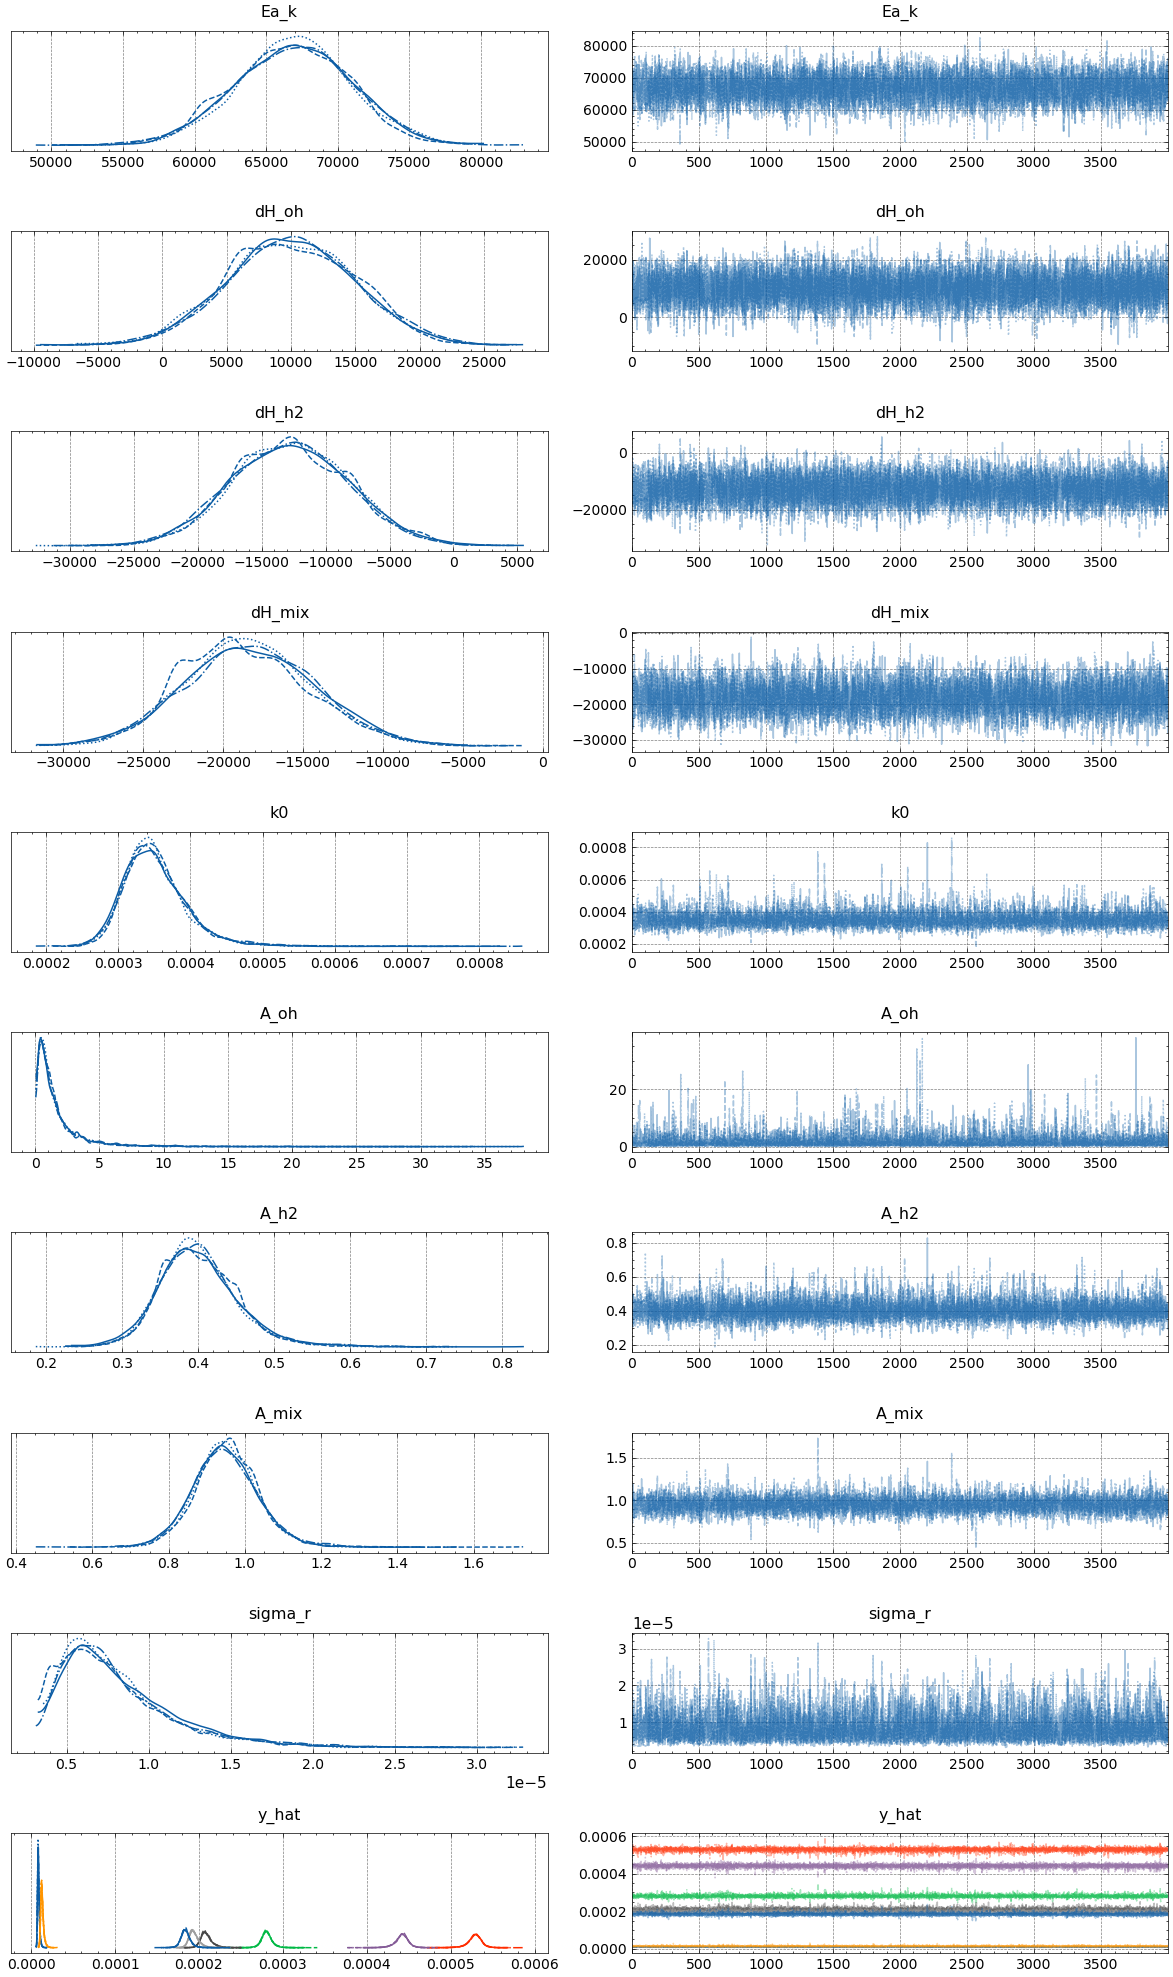

In [45]:
az.plot_trace(idata, divergences=False)
plt.show()

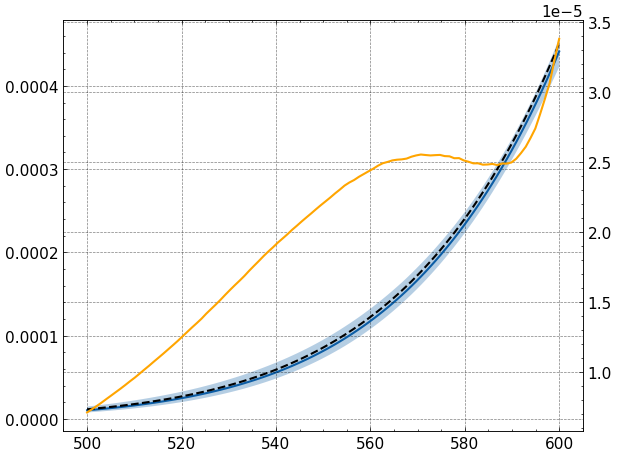

In [46]:
test_res = post_model_over_T(proposals[4], idata, key="posterior")
true_res = true_model_over_T(proposals[4])
plot_post_model_at_proposal(test_res, true_res, Ts)

In [47]:
sol = minimize(
    max_func,
    jnp.array([555.0, 10.0, 1.0, 100, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[5.00000000e+02, 4.00000000e+00, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 4.00000000e+00, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [5.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        5.00000000e-01],
       [6.00000000e+02, 2.00000000e+01, 1.99999683e+00, 1.00000000e+03,
        9.99979096e-01],
       [5.69013891e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [5.74456740e+02, 2.00000000e+01, 2.00000000e+00, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 3.28278965e+00, 1.73911836e+00, 8.92865756e+01,
        4.03215669e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00]])

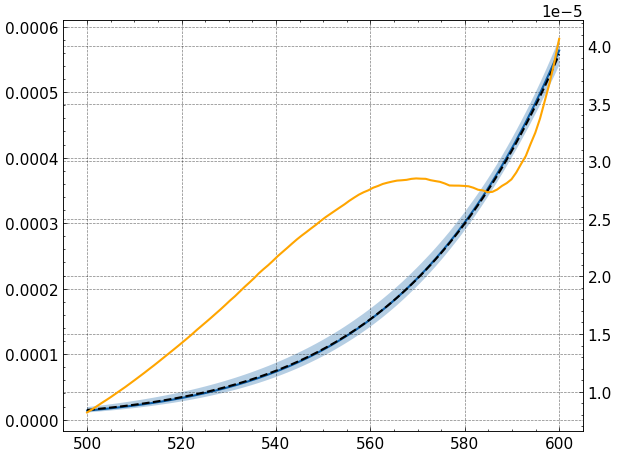

In [48]:
test_res = post_model_over_T(proposals[5], idata, key="posterior")
true_res = true_model_over_T(proposals[5])
plot_post_model_at_proposal(test_res, true_res, Ts)

## Sixth Conditioning Step


In [50]:
T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 117 seconds.
There were 75 divergences after tuning. Increase `target_accept` or reparameterize.


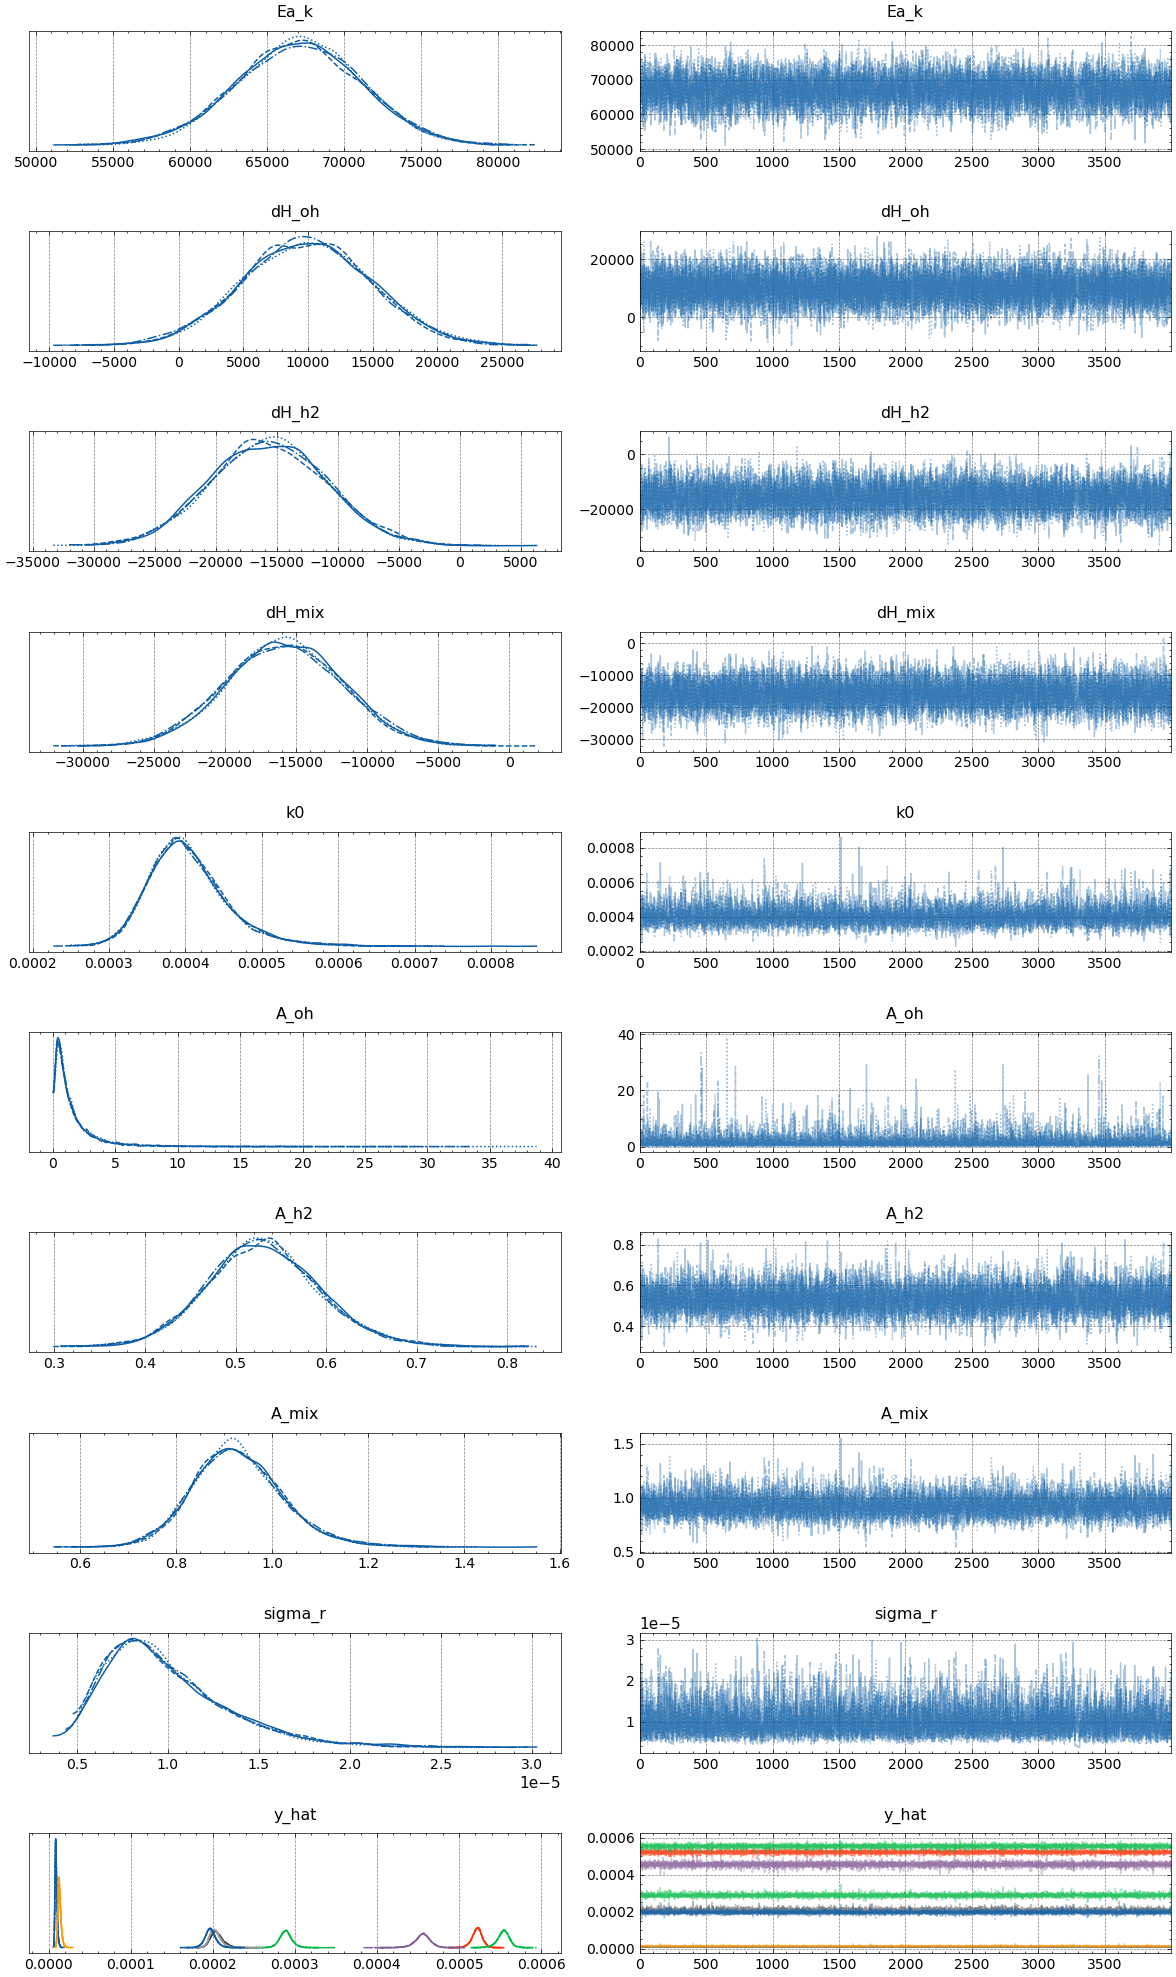

In [51]:
az.plot_trace(idata, divergences=False)
plt.show()

In [ ]:
test_res = post_model_over_T(proposals[5], idata, key="posterior")
true_res = true_model_over_T(proposals[5])
plot_post_model_at_proposal(test_res, true_res, Ts)

In [ ]:
sol = minimize(
    max_func,
    jnp.array([555.0, 10.0, 1.0, 100, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

In [ ]:
test_res = post_model_over_T(proposals[6], idata, key="posterior")
true_res = true_model_over_T(proposals[6])
plot_post_model_at_proposal(test_res, true_res, Ts)

In [ ]:
display(pm.summary(idata, hdi_prob=0.95))

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Ea_k,65109.608,4597.073,55928.307,73807.187,63.568,41.910,5131.0,6090.0,1.0
dH_oh,9973.593,4977.044,396.098,19655.678,63.044,52.469,6261.0,5592.0,1.0
dH_h2,-14418.103,4824.233,-24106.010,-5313.214,60.792,43.927,6277.0,5898.0,1.0
dH_mix,-14320.751,4808.865,-23746.794,-4713.702,66.968,58.881,5214.0,3291.0,1.0
k0,0.001,0.000,0.000,0.001,0.000,0.000,4964.0,5523.0,1.0
A_oh,1.663,2.271,0.024,5.185,0.039,0.127,6748.0,5494.0,1.0
A_h2,0.729,0.129,0.491,0.998,0.002,0.002,5926.0,7288.0,1.0
A_mix,1.036,0.158,0.724,1.354,0.002,0.002,6701.0,7876.0,1.0
sigma_r,0.000,0.000,0.000,0.000,0.000,0.000,1995.0,1098.0,1.0
"y_hat[0, 0]",0.001,0.000,0.001,0.001,0.000,0.000,10327.0,9228.0,1.0
